# Pipeline final de análise espectral

## Parte 1 — importação, limpeza e pré-processamento

Esta etapa parte de `dataset/Unificada13052026.csv` e executa a limpeza de metadados e todo o pré-processamento espectral **neste notebook**. As próximas análises serão incorporadas em etapas posteriores.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from scipy.signal import savgol_filter


def localizar_raiz(inicio: Path | None = None) -> Path:
    """Permite iniciar o kernel na raiz do projeto ou em script_final."""
    inicio = (inicio or Path.cwd()).resolve()
    for candidato in (inicio, *inicio.parents):
        if (candidato / "dataset/Unificada13052026.csv").is_file():
            return candidato
    raise FileNotFoundError("Arquivo dataset/Unificada13052026.csv não encontrado.")


ROOT = localizar_raiz()
ARQUIVO_ENTRADA = ROOT / "dataset/Unificada13052026.csv"
print(f"Base de entrada: {ARQUIVO_ENTRADA}")


Base de entrada: C:\Users\muril\Documents\EstresseHidricoFinal\dataset\Unificada13052026.csv


### 1. Limpeza dos metadados

A identificação registrada em `nomenclaura` corrige divergências em `genotipo` e `condicao`; o bloco passa a usar maiúsculas, e o erro `C202` é corrigido para `CD202`. Os valores espectrais permanecem intactos.


In [2]:
def limpar_metadados(df: pd.DataFrame) -> pd.DataFrame:
    """Reproduz as quatro correções de dataset/limpar_metadados.py."""
    df = df.copy()
    df["bloco"] = df["bloco"].str.upper()

    tokens = df["nomenclaura"].str.split("_")
    typo_c202 = tokens.str[1] == "C202"
    tokens.loc[typo_c202] = tokens.loc[typo_c202].apply(
        lambda t: [t[0], "CD202", *t[2:]]
    )
    df.loc[typo_c202, "nomenclaura"] = tokens.loc[typo_c202].str.join("_")

    genotipo_nomenclaura = tokens.str[1]
    genotipos_validos = {"BR16", "CD202", "EMB48"}
    divergente = genotipo_nomenclaura.isin(genotipos_validos) & (
        genotipo_nomenclaura != df["genotipo"]
    )
    df.loc[divergente, "genotipo"] = genotipo_nomenclaura[divergente]

    condicoes_validas = {
        "IRRIG": "IRRIG", "NIRRIG": "NIRRIG",
        "IRR": "IRRIG", "NIRR": "NIRRIG",
    }
    condicao_nomenclaura = tokens.str[2].map(condicoes_validas)
    divergente = condicao_nomenclaura.notna() & (
        condicao_nomenclaura != df["condicao"]
    )
    df.loc[divergente, "condicao"] = condicao_nomenclaura[divergente]
    return df


In [3]:
base_bruta = pd.read_csv(ARQUIVO_ENTRADA, sep=";", decimal=",")
base_bruta.columns = base_bruta.columns.str.strip()
base_limpa = limpar_metadados(base_bruta)

colunas_metadados = [c for c in base_limpa.columns if not c.isdigit()]
colunas_espectrais = sorted((c for c in base_limpa.columns if c.isdigit()), key=int)
correcoes = {
    coluna: int((base_bruta[coluna] != base_limpa[coluna]).sum())
    for coluna in ("bloco", "genotipo", "nomenclaura", "condicao")
}
print(f"Amostras: {len(base_limpa)} | Metadados: {len(colunas_metadados)}")
print(f"Bandas originais: {len(colunas_espectrais)} ({colunas_espectrais[0]}–{colunas_espectrais[-1]} nm)")
display(pd.DataFrame(correcoes.items(), columns=["metadado", "linhas corrigidas"]))


Amostras: 1924 | Metadados: 6
Bandas originais: 2151 (350–2500 nm)


,metadado,linhas corrigidas
0,bloco,192
1,genotipo,32
2,nomenclaura,16
3,condicao,16


### 2. Pré-processamento espectral

O fluxo usa as mesmas regras do projeto: recorte de 400 a 2450 nm, limite absoluto de 10.000 para valores extremos, correção das emendas dos detectores em 1000 e 1800 nm, interpolação dos ausentes, filtro Savitzky–Golay (janela 11, polinômio 2) e SNV por amostra.


In [4]:
LIMITE_INF, LIMITE_SUP = 400, 2450
SPLICE_POINTS = (1000, 1800)
REFERENCE_SEQ = 1
CLIP_ABS = 1e4
WINDOW_LENGTH, POLYORDER, MODE = 11, 2, "interp"


def jump_correct(series: pd.Series) -> pd.Series:
    """Alinha os três detectores por deslocamento nas emendas."""
    series = series.sort_index()

    def get_seq(wl: float) -> int:
        for i, splice in enumerate(SPLICE_POINTS):
            if wl <= splice:
                return i
        return len(SPLICE_POINTS)

    groups = series.groupby(get_seq)

    def shift(ref: pd.Series, mov: pd.Series, right: bool = True) -> pd.Series:
        diff = (ref.iloc[-1] - mov.iloc[0]) if right else (ref.iloc[0] - mov.iloc[-1])
        return mov + diff

    for i in range(REFERENCE_SEQ, groups.ngroups - 1):
        series.update(shift(groups.get_group(i), groups.get_group(i + 1)))
    for i in range(REFERENCE_SEQ, 0, -1):
        series.update(shift(groups.get_group(i), groups.get_group(i - 1), right=False))
    return series


def limpar_valores_espurios(espectro: np.ndarray) -> np.ndarray:
    espectro = np.clip(espectro.copy(), -CLIP_ABS, CLIP_ABS)
    espectro[~np.isfinite(espectro)] = np.nan
    return espectro


def interpolar(espectro: np.ndarray) -> np.ndarray:
    espectro = espectro.copy()
    for i in range(espectro.shape[0]):
        linha = espectro[i]
        if np.isnan(linha).any():
            espectro[i] = pd.Series(linha).interpolate(limit_direction="both").to_numpy()
    return np.nan_to_num(espectro, nan=0.0, posinf=0.0, neginf=0.0)


def preprocessar(df: pd.DataFrame) -> tuple[pd.DataFrame, np.ndarray]:
    """Recorta, limpa, corrige as emendas e interpola os espectros."""
    meta = [c for c in df.columns if not c.isdigit()]
    bandas = sorted(int(c) for c in df.columns if c.isdigit())
    bandas_validas = [b for b in bandas if LIMITE_INF <= b <= LIMITE_SUP]
    if not bandas_validas:
        raise ValueError("Nenhuma banda entre 400 e 2450 nm foi encontrada.")
    w = np.array(bandas_validas, dtype=float)

    espectro = df[[str(b) for b in bandas_validas]].to_numpy(dtype=float)
    espectro_limpo = limpar_valores_espurios(espectro)
    espectro_corrigido = np.zeros_like(espectro_limpo)
    for i in range(espectro_limpo.shape[0]):
        serie = pd.Series(espectro_limpo[i], index=w, dtype="float64")
        espectro_corrigido[i] = jump_correct(serie).to_numpy()

    df_espectro = pd.DataFrame(
        interpolar(espectro_corrigido),
        columns=[str(b) for b in bandas_validas], index=df.index,
    )
    return pd.concat([df[meta], df_espectro], axis=1), w


def savitzky_golay(espectro: np.ndarray) -> np.ndarray:
    """Suaviza cada amostra com Savitzky–Golay."""
    window = WINDOW_LENGTH + (WINDOW_LENGTH % 2 == 0)
    min_window = POLYORDER + 2 if (POLYORDER + 2) % 2 else POLYORDER + 3
    window = max(window, min_window)
    suavizado = np.zeros_like(espectro)
    for i, linha in enumerate(espectro):
        suavizado[i] = (
            savgol_filter(linha, window, POLYORDER, mode=MODE)
            if len(linha) >= window else linha
        )
    return suavizado


def snv(espectro: np.ndarray) -> np.ndarray:
    """Centraliza e escala cada espectro por seu desvio padrão."""
    normalizado = np.zeros_like(espectro)
    for i, linha in enumerate(espectro):
        media, desvio = np.nanmean(linha), np.nanstd(linha)
        normalizado[i] = (
            (linha - media) / desvio
            if desvio > 0 and np.isfinite(desvio) else linha - media
        )
    return normalizado


In [5]:
base_recortada, comprimentos_onda = preprocessar(base_limpa)
bandas_processadas = [str(int(w)) for w in comprimentos_onda]

base_suavizada = base_recortada.copy()
base_suavizada[bandas_processadas] = savitzky_golay(
    base_recortada[bandas_processadas].to_numpy(dtype=float)
)

base_normalizada = base_suavizada.copy()
base_normalizada[bandas_processadas] = snv(
    base_suavizada[bandas_processadas].to_numpy(dtype=float)
)

print(f"Pré-processamento concluído: {len(base_normalizada)} amostras, "
      f"{len(bandas_processadas)} bandas ({int(comprimentos_onda[0])}–{int(comprimentos_onda[-1])} nm).")


Pré-processamento concluído: 1924 amostras, 2051 bandas (400–2450 nm).


In [6]:
resumo_preprocessamento = pd.DataFrame([
    {
        "estágio": nome,
        "amostras": len(base),
        "bandas": len(bandas_processadas),
        "ausentes": int(base[bandas_processadas].isna().sum().sum()),
    }
    for nome, base in (
        ("corrigido e recortado", base_recortada),
        ("suavizado", base_suavizada),
        ("normalizado (SNV)", base_normalizada),
    )
])
display(resumo_preprocessamento)


,estágio,amostras,bandas,ausentes
0,corrigido e recortado,1924,2051,0
1,suavizado,1924,2051,0
2,normalizado (SNV),1924,2051,0


## Parte 2 — dispersão espectral por genótipo e dia

Uma figura por genótipo compara os sete dias de coleta matinal. Cada linha mostra um dia; as colunas mostram o espectro corrigido e recortado e o espectro suavizado e normalizado. Azul representa IRRIG e laranja, NIRRIG. A linha contínua é a média, as tracejadas delimitam o intervalo de confiança de 95% da média, e as pontilhadas mostram o mínimo e o máximo das leituras em cada banda.

Os gráficos usam diretamente `base_recortada` e `base_normalizada`, geradas acima. Nenhum script ou CSV intermediário é carregado.


In [7]:
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import t as t_dist

CONDICOES = ("IRRIG", "NIRRIG")
COR_CONDICAO = {"IRRIG": "#2a78d6", "NIRRIG": "#eb6834"}
CONFIANCA = 0.95
ESTAGIOS_GRAFICO = (
    ("recortado", "Recortado (recorte + correção das emendas)", "Reflectância"),
    ("normalizado", "Normalizado (Savitzky–Golay + SNV)", "Reflectância (SNV)"),
)
EXIBIR_GRAFICOS = True
SALVAR_GRAFICOS = True
PASTA_GRAFICOS = ROOT / "script_final/outputs/dispersoes"

mascara_manha = base_limpa["turno"].eq("manha")
meta_graficos = base_limpa.loc[
    mascara_manha, ["genotipo", "condicao", "data_coleta", "turno"]
].copy().reset_index(drop=True)
meta_graficos["dia"] = meta_graficos["data_coleta"].astype(str).str.extract(r"^(D\d+)")
if meta_graficos["dia"].isna().any():
    raise ValueError("Há códigos de data_coleta sem dia no formato Dxx.")

espectros_graficos = {
    "recortado": base_recortada.loc[mascara_manha, bandas_processadas].to_numpy(dtype=float),
    "normalizado": base_normalizada.loc[mascara_manha, bandas_processadas].to_numpy(dtype=float),
}
dias_graficos = sorted(meta_graficos["dia"].unique())
genotipos_graficos = sorted(meta_graficos["genotipo"].unique())
if not dias_graficos or not genotipos_graficos:
    raise ValueError("Nenhuma amostra matinal encontrada para os gráficos.")

contagens_graficos = (
    meta_graficos.groupby(["genotipo", "dia", "condicao"]).size()
    .rename("leituras").reset_index()
)
display(contagens_graficos.pivot(index=["genotipo", "dia"], columns="condicao", values="leituras"))


condicao      IRRIG  NIRRIG
genotipo dia               
BR16     D02     32      32
         D03     32      32
         D04     32      32
         D05     32      32
         D06     32      32
         D09     32      32
         D10     32      32
CD202    D02     32      32
         D03     32      32
         D04     32      32
         D05     32      32
         D06     32      32
         D09     36      32
         D10     32      32
EMB48    D02     32      32
         D03     32      32
         D04     32      32
         D05     32      32
         D06     32      32
         D09     32      32
         D10     32      32

In [8]:
def resumo_banda(espectro: np.ndarray) -> dict[str, np.ndarray | int]:
    """Média, IC t de Student de 95% da média e extremos por banda."""
    n = espectro.shape[0]
    if n == 0:
        raise ValueError("Não é possível resumir um grupo sem leituras.")
    media = espectro.mean(axis=0)
    minimo = espectro.min(axis=0)
    maximo = espectro.max(axis=0)
    if n > 1:
        erro = espectro.std(axis=0, ddof=1) / np.sqrt(n)
        margem = t_dist.ppf(0.5 + CONFIANCA / 2, df=n - 1) * erro
    else:
        margem = np.zeros_like(media)
    return {
        "media": media, "ic_inf": media - margem, "ic_sup": media + margem,
        "min": minimo, "max": maximo, "n": n,
    }


def plot_celula(ax: plt.Axes, w: np.ndarray, resumos: dict, titulo: str, unidade: str) -> None:
    """Desenha as duas condições em um dia e estágio."""
    for condicao in CONDICOES:
        if condicao not in resumos:
            continue
        cor, r = COR_CONDICAO[condicao], resumos[condicao]
        ax.plot(w, r["min"], color=cor, linewidth=0.7, linestyle=(0, (1, 2)))
        ax.plot(w, r["max"], color=cor, linewidth=0.7, linestyle=(0, (1, 2)))
        ax.plot(w, r["ic_inf"], color=cor, linewidth=1.1, linestyle=(0, (6, 4)))
        ax.plot(w, r["ic_sup"], color=cor, linewidth=1.1, linestyle=(0, (6, 4)))

    for condicao in CONDICOES:
        if condicao not in resumos:
            continue
        ax.plot(
            w, resumos[condicao]["media"], color=COR_CONDICAO[condicao],
            linewidth=2.2, solid_capstyle="round",
            path_effects=[pe.Stroke(linewidth=3.0, foreground="white"), pe.Normal()],
        )
    ax.set_title(titulo, fontsize=10, fontweight="bold")
    ax.set_xlabel("Comprimento de onda (nm)", fontsize=8)
    ax.set_ylabel(unidade, fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.tick_params(labelsize=7)


def legenda_figura(fig: plt.Figure) -> None:
    handles = [
        Line2D([], [], color=COR_CONDICAO[c], linewidth=2.2, label=c)
        for c in CONDICOES
    ] + [
        Line2D([], [], color="#555555", linewidth=2.2, label="Média"),
        Line2D([], [], color="#555555", linewidth=1.1, linestyle=(0, (6, 4)),
               label="IC 95% da média"),
        Line2D([], [], color="#555555", linewidth=0.7, linestyle=(0, (1, 2)),
               label="Mínimo / máximo"),
    ]
    fig.legend(handles=handles, loc="lower center", ncol=len(handles),
               frameon=False, fontsize=10)


def gerar_figura_genotipo(genotipo: str) -> plt.Figure:
    """Cria o painel 7 × 2 de um genótipo usando os espectros já processados."""
    do_genotipo = meta_graficos["genotipo"].eq(genotipo).to_numpy()
    resumos = {}
    for chave, _, _ in ESTAGIOS_GRAFICO:
        for dia in dias_graficos:
            do_dia = do_genotipo & meta_graficos["dia"].eq(dia).to_numpy()
            por_condicao = {}
            for condicao in CONDICOES:
                mascara = do_dia & meta_graficos["condicao"].eq(condicao).to_numpy()
                if mascara.any():
                    por_condicao[condicao] = resumo_banda(espectros_graficos[chave][mascara])
            if por_condicao:
                resumos[(chave, dia)] = por_condicao

    limites = {}
    for chave, _, _ in ESTAGIOS_GRAFICO:
        valores = np.concatenate([
            r[k] for (estagio, _), por_condicao in resumos.items() if estagio == chave
            for r in por_condicao.values() for k in ("min", "max")
        ])
        folga = 0.05 * (valores.max() - valores.min())
        limites[chave] = (valores.min() - folga, valores.max() + folga)

    with plt.style.context("seaborn-v0_8-whitegrid"):
        fig, axes = plt.subplots(
            len(dias_graficos), len(ESTAGIOS_GRAFICO),
            figsize=(7.5 * len(ESTAGIOS_GRAFICO), 3.4 * len(dias_graficos)),
            squeeze=False,
        )
        for i, dia in enumerate(dias_graficos):
            for j, (chave, rotulo, unidade) in enumerate(ESTAGIOS_GRAFICO):
                ax = axes[i, j]
                resumo = resumos.get((chave, dia))
                if resumo is None:
                    ax.set_axis_off()
                    continue
                ns = ", ".join(
                    f"{c} n={resumo[c]['n']}" for c in CONDICOES if c in resumo
                )
                plot_celula(ax, comprimentos_onda, resumo,
                            f"{dia} - {rotulo} ({ns})", unidade)
                ax.set_ylim(*limites[chave])
        legenda_figura(fig)
        fig.suptitle(
            f"Genótipo {genotipo} — dispersão espectral dia a dia\n"
            "Turno da manhã; escala vertical compartilhada por estágio",
            fontsize=14, fontweight="bold",
        )
        fig.tight_layout(rect=[0, 0.025, 1, 0.975])
    return fig


BR16: script_final\outputs\dispersoes\dispersao_dia_BR16.png


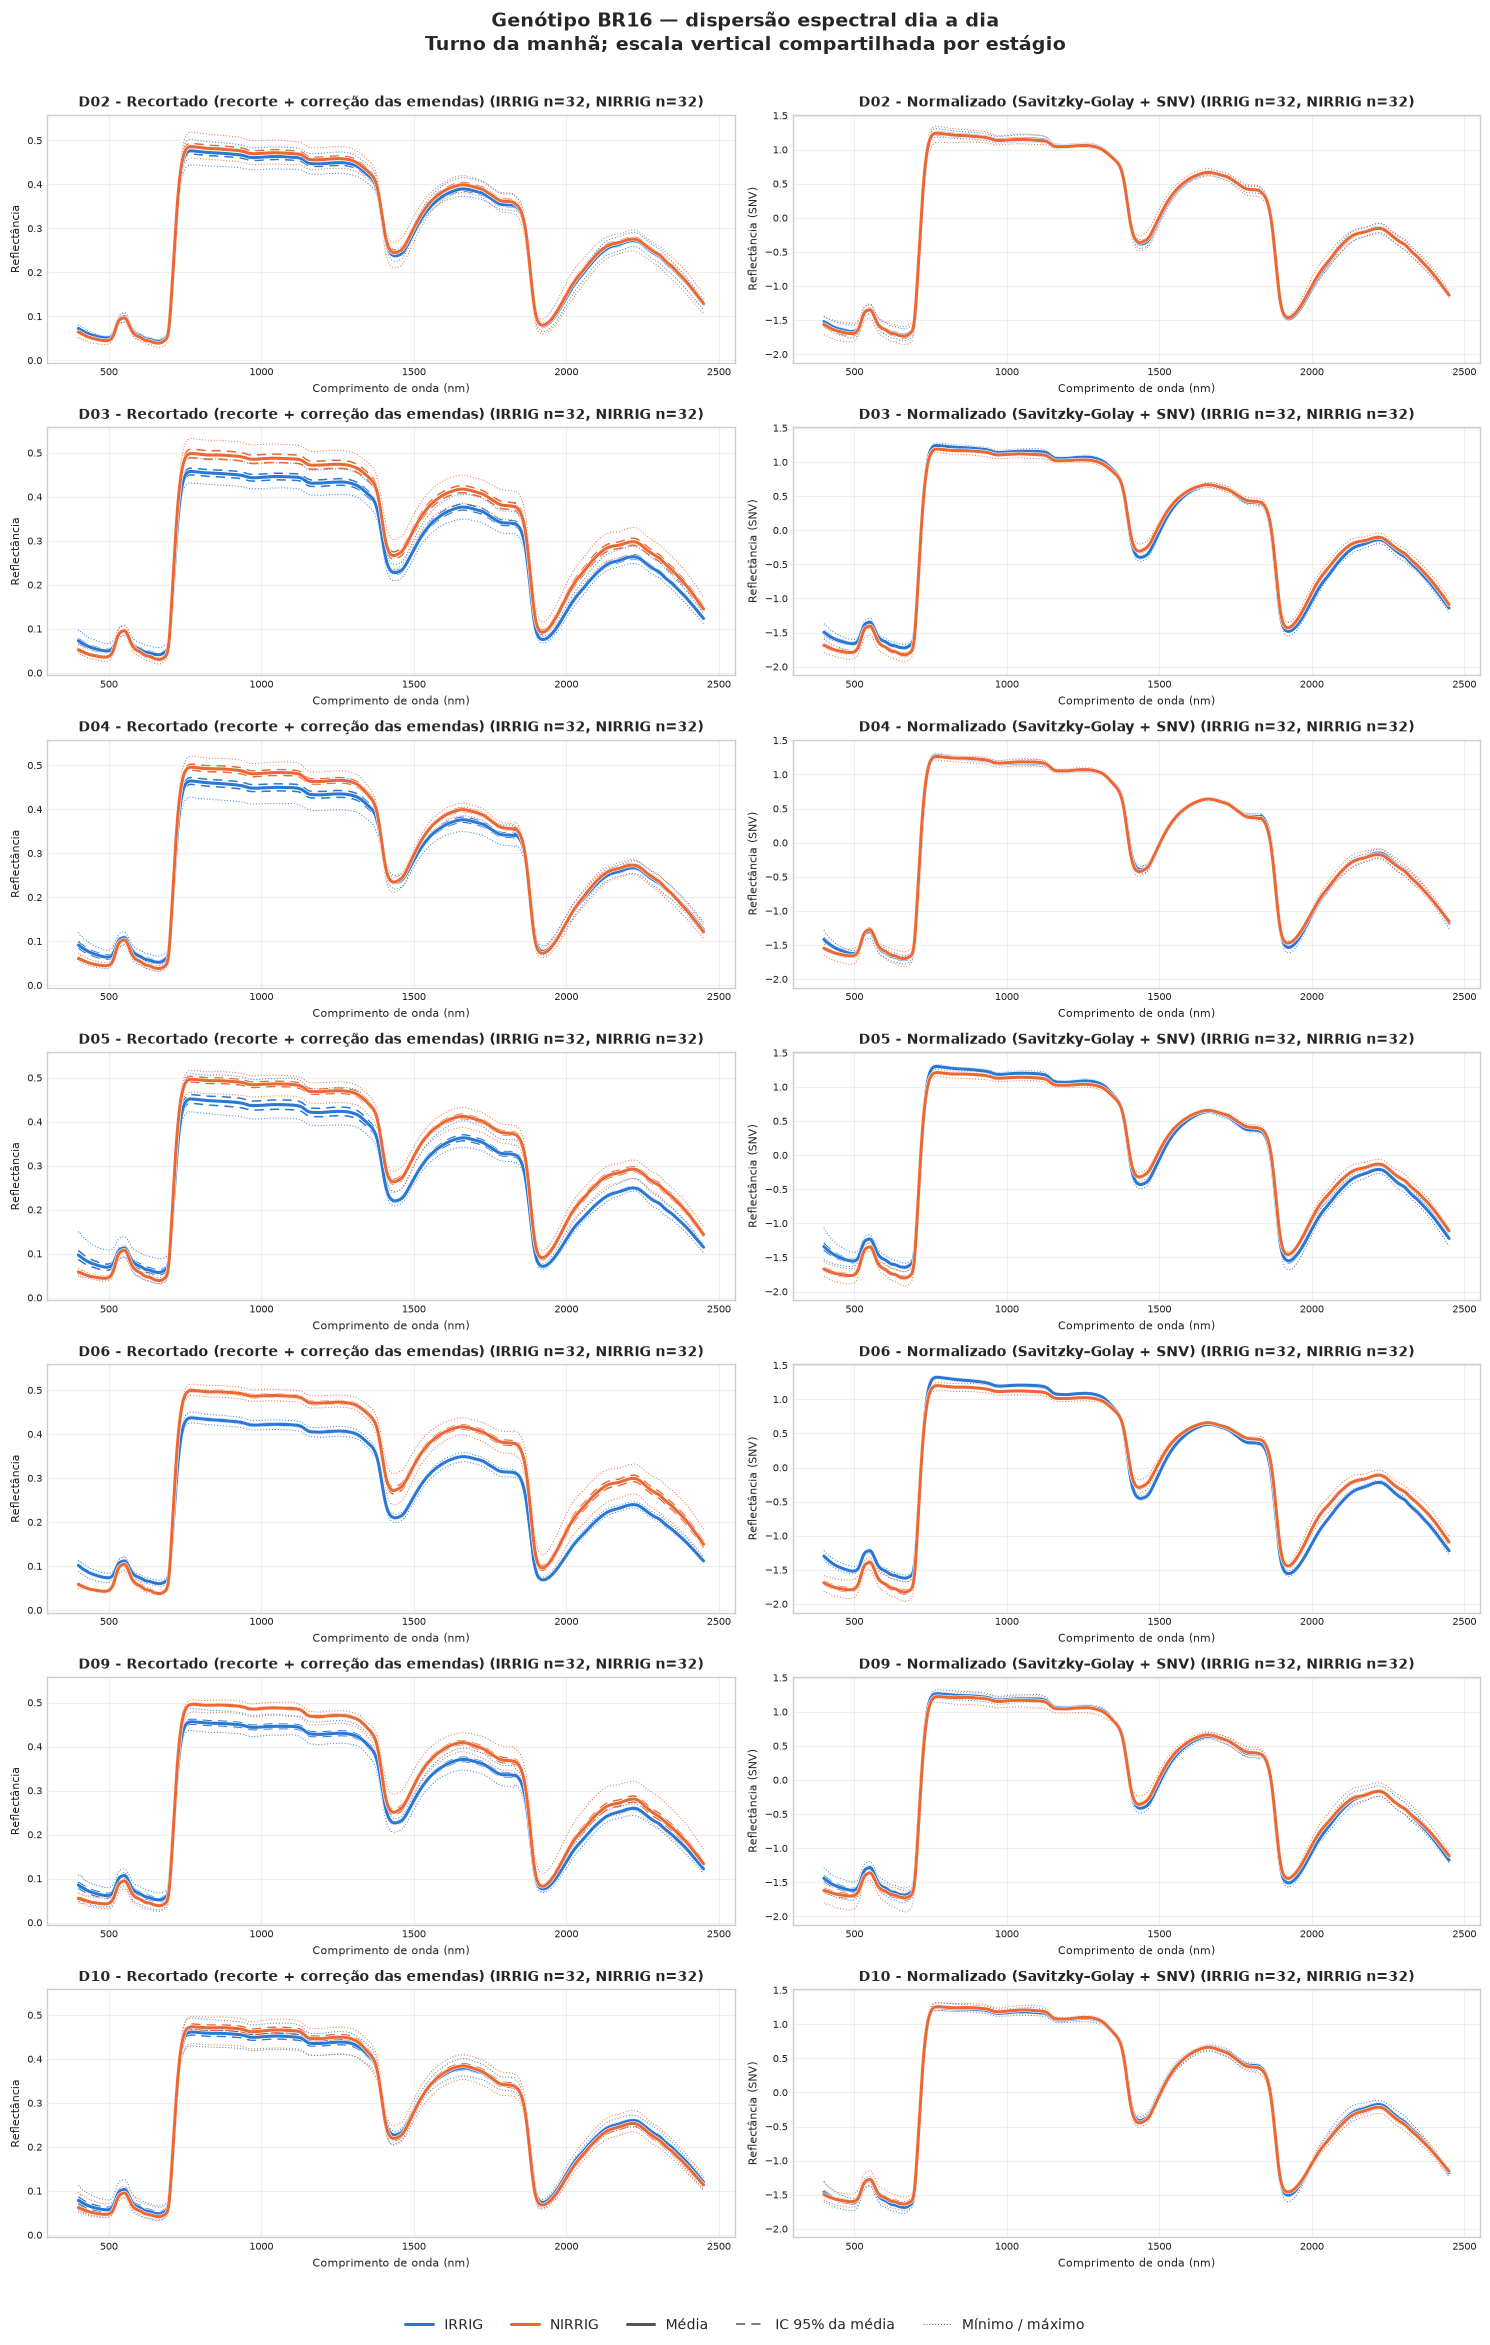

CD202: script_final\outputs\dispersoes\dispersao_dia_CD202.png


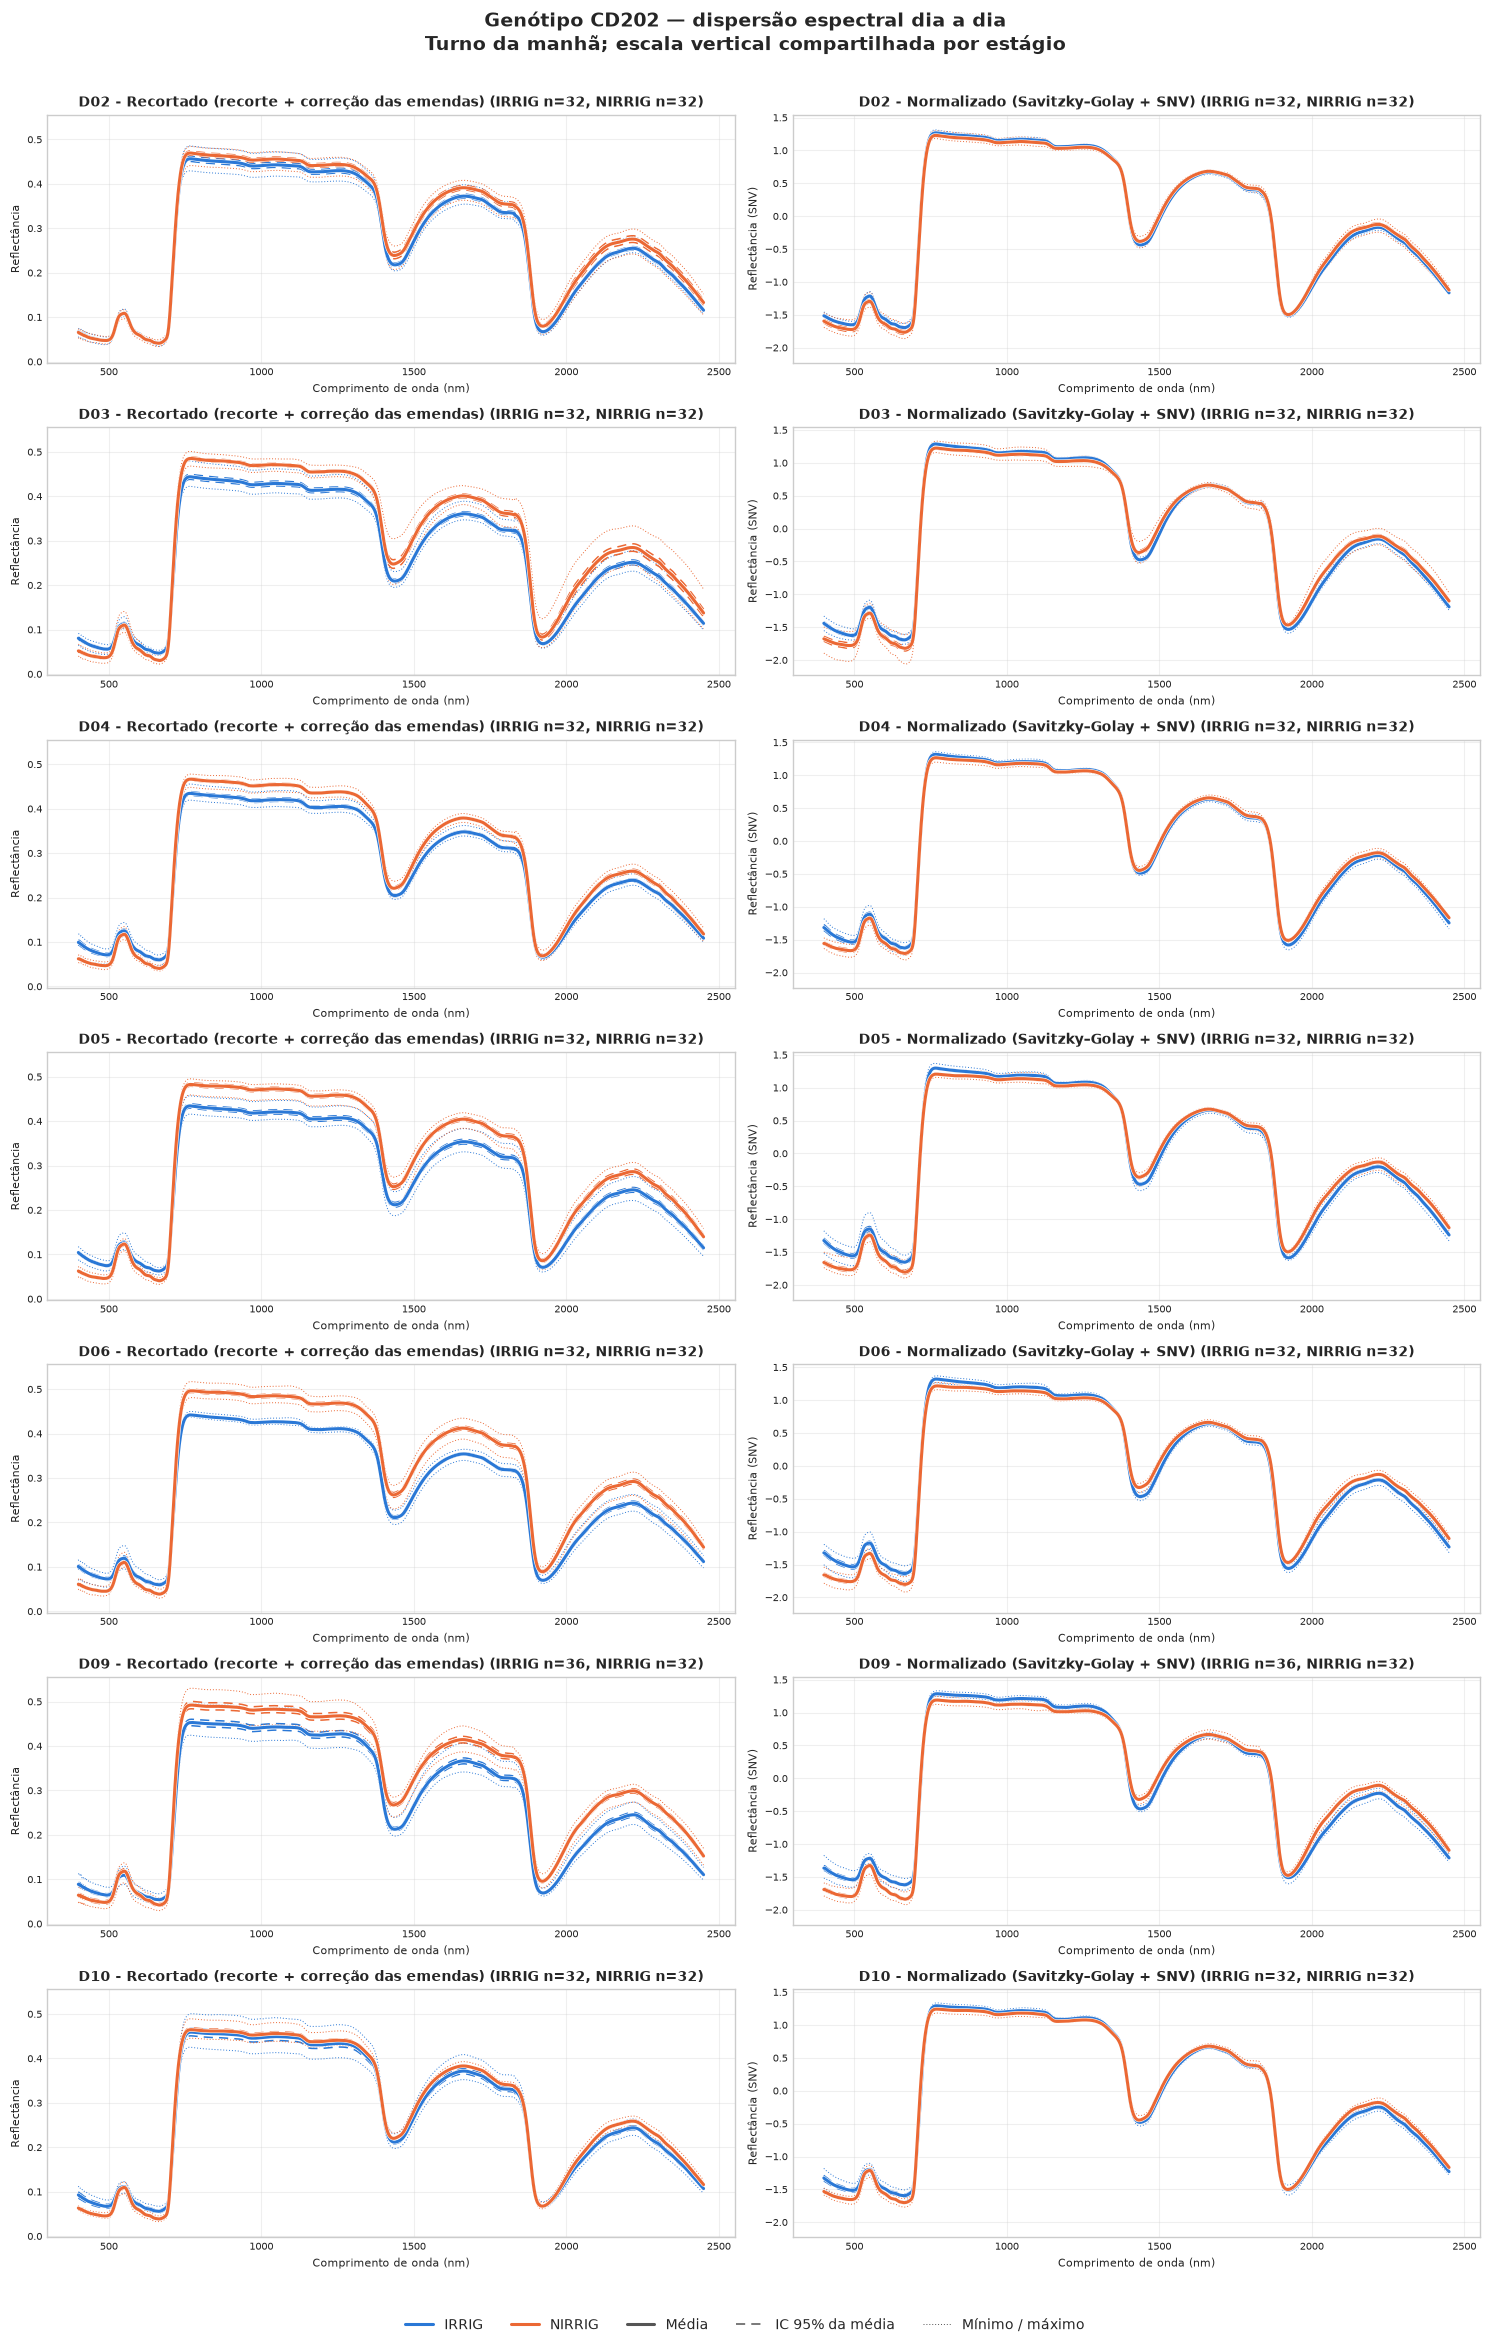

EMB48: script_final\outputs\dispersoes\dispersao_dia_EMB48.png


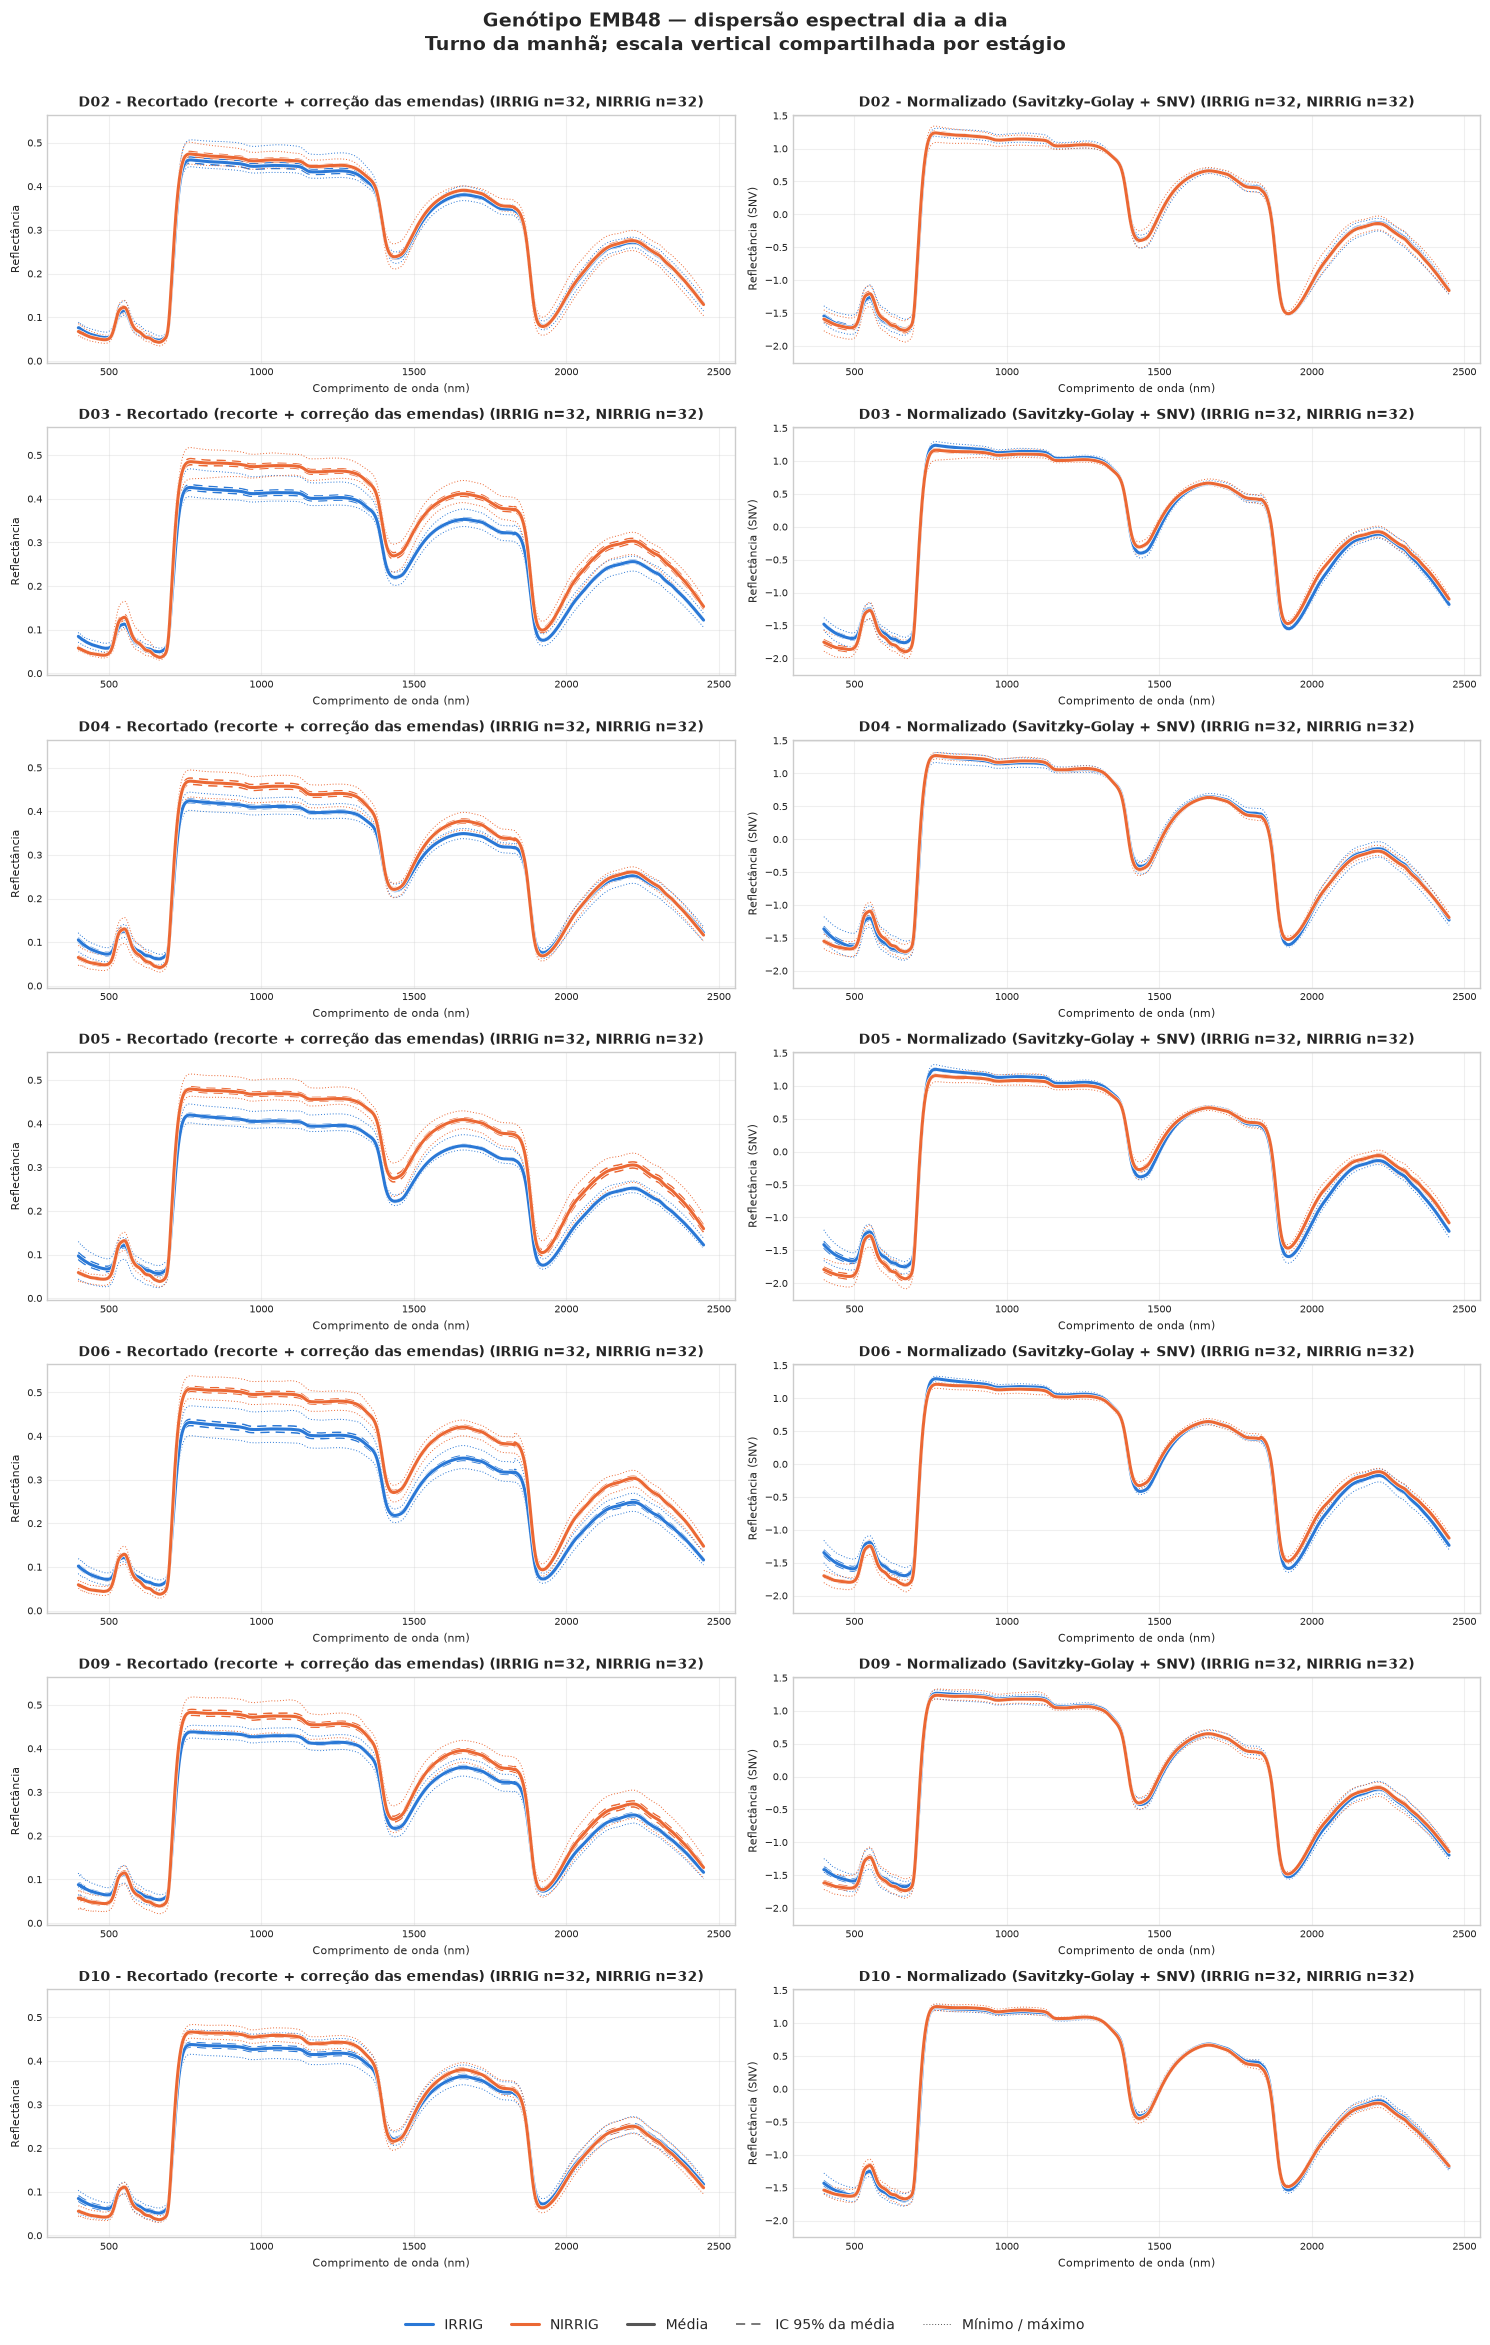

In [9]:
if SALVAR_GRAFICOS:
    PASTA_GRAFICOS.mkdir(parents=True, exist_ok=True)

arquivos_graficos = {}
for genotipo in genotipos_graficos:
    figura = gerar_figura_genotipo(genotipo)
    if SALVAR_GRAFICOS:
        arquivo = PASTA_GRAFICOS / f"dispersao_dia_{genotipo}.png"
        figura.savefig(arquivo, dpi=150, bbox_inches="tight")
        arquivos_graficos[genotipo] = arquivo
        print(f"{genotipo}: {arquivo.relative_to(ROOT)}")
    if EXIBIR_GRAFICOS:
        display(figura)
    plt.close(figura)


## Parte 3 — classificação IRRIG × NIRRIG por dia

Os três genótipos são reunidos **dentro de cada dia**; somente as leituras da manhã entram na análise. Em cada dia, bandas contíguas com correlação de Spearman `|ρ| > 0,80` são agrupadas por ligação completa dentro de uma janela menor que 10 nm. A banda central de cada grupo representa a região. Uma Random Forest ajustada naquele dia ranqueia essas representantes por importância Gini e define as cinco bandas do modelo XGBoost daquele dia. **NIRRIG é a classe positiva.**

Para avaliar a classificação, cada um dos quatro blocos fica fora do treino uma vez. A redução por Spearman e a seleção por Random Forest são refeitas **somente com os dados de treino de cada dobra**; o XGBoost prevê as leituras do bloco excluído. Assim, as métricas de validação não usam bandas escolhidas com acesso ao bloco de teste. A tabela de importância exibida para cada dia vem de um ajuste final com todas as leituras daquele dia e determina as cinco bandas do modelo final correspondente.


In [10]:
from scipy.stats import rankdata
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import GroupKFold
from xgboost import XGBClassifier

LIMIAR_SPEARMAN = 0.80
JANELA_SPEARMAN_NM = 10.0
TOP_K = 5
N_ARVORES_RF = 200
N_ARVORES_XGB = 150
SEMENTE_CLASSIFICACAO = 42
PASTA_CLASSIFICACAO = ROOT / "script_final/outputs/classificacao"


def reduzir_spearman(X: np.ndarray, w: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Agrupa bandas vizinhas com |ρ| > 0,80 contra todos os membros do grupo."""
    postos = rankdata(X, axis=0, method="average")
    z = postos - postos.mean(axis=0)
    norma = np.sqrt((z ** 2).sum(axis=0))
    norma[norma == 0] = np.inf
    z /= norma

    grupos = np.zeros(len(w), dtype=int)
    membros = [0]
    atual = 0
    for j in range(1, len(w)):
        dentro_janela = w[j] - w[membros[0]] < JANELA_SPEARMAN_NM
        correlacionada = dentro_janela and np.all(
            np.abs(z[:, membros].T @ z[:, j]) > LIMIAR_SPEARMAN
        )
        if correlacionada:
            membros.append(j)
        else:
            atual += 1
            membros = [j]
        grupos[j] = atual

    representantes = np.array([
        indices[len(indices) // 2]
        for grupo in range(atual + 1)
        if (indices := np.flatnonzero(grupos == grupo)).size
    ], dtype=int)
    return grupos, representantes


def selecionar_top5_rf(
    X: np.ndarray, y: np.ndarray, w: np.ndarray, semente: int
) -> tuple[pd.DataFrame, np.ndarray, np.ndarray, np.ndarray]:
    """Reduz bandas e ranqueia as representantes pela importância Gini da RF."""
    grupos, representantes = reduzir_spearman(X, w)
    if len(representantes) < TOP_K:
        raise ValueError(f"A redução de Spearman deixou apenas {len(representantes)} bandas.")
    rf = RandomForestClassifier(
        n_estimators=N_ARVORES_RF, max_features="sqrt",
        class_weight="balanced", random_state=semente, n_jobs=1,
    ).fit(X[:, representantes], y)
    importancia = rf.feature_importances_
    ordem = np.lexsort((w[representantes], -importancia))
    tabela = pd.DataFrame({
        "posicao": np.arange(1, len(ordem) + 1),
        "banda_nm": w[representantes][ordem].astype(int),
        "importancia_gini": importancia[ordem],
    })
    return tabela, representantes[ordem[:TOP_K]], grupos, representantes


def novo_xgboost(y_treino: np.ndarray, semente: int) -> XGBClassifier:
    negativos = int((y_treino == 0).sum())
    positivos = int((y_treino == 1).sum())
    return XGBClassifier(
        n_estimators=N_ARVORES_XGB, max_depth=3, learning_rate=0.05,
        subsample=0.8, colsample_bytree=1.0, reg_lambda=1.0,
        scale_pos_weight=negativos / positivos,
        objective="binary:logistic", eval_metric="logloss",
        tree_method="hist", n_jobs=1, random_state=semente,
    )


def calcular_metricas(y_real: np.ndarray, y_pred: np.ndarray, prob: np.ndarray) -> dict:
    tn, fp, fn, tp = confusion_matrix(y_real, y_pred, labels=[0, 1]).ravel()
    return {
        "acuracia": accuracy_score(y_real, y_pred),
        "acuracia_balanceada": balanced_accuracy_score(y_real, y_pred),
        "precisao_nirrig": precision_score(y_real, y_pred, zero_division=0),
        "sensibilidade_nirrig": recall_score(y_real, y_pred, zero_division=0),
        "f1_nirrig": f1_score(y_real, y_pred, zero_division=0),
        "auc_roc": roc_auc_score(y_real, prob),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }


ModuleNotFoundError: No module named 'xgboost'

In [ ]:
# Este ramo usa somente as bases produzidas na parte 1, sem arquivos intermediários.
mascara_classificacao = base_limpa["turno"].eq("manha")
meta_classificacao = base_limpa.loc[
    mascara_classificacao, ["bloco", "genotipo", "condicao", "data_coleta"]
].copy().reset_index(drop=True)
meta_classificacao["dia"] = (
    meta_classificacao["data_coleta"].astype(str).str.extract(r"^(D\d+)")
)
if meta_classificacao["dia"].isna().any():
    raise ValueError("Há códigos de data_coleta sem dia no formato Dxx.")
X_classificacao = base_normalizada.loc[
    mascara_classificacao, bandas_processadas
].to_numpy(dtype=float)
y_classificacao = meta_classificacao["condicao"].eq("NIRRIG").astype(int).to_numpy()
if not set(meta_classificacao["condicao"].unique()).issubset({"IRRIG", "NIRRIG"}):
    raise ValueError("Foram encontradas condições diferentes de IRRIG e NIRRIG.")

PASTA_CLASSIFICACAO.mkdir(parents=True, exist_ok=True)
importancias_rf_por_dia = {}
modelos_xgboost_por_dia = {}
top5_tabelas, metricas_dias, metricas_dobras, predicoes_dias = [], [], [], []

for numero_dia, dia in enumerate(sorted(meta_classificacao["dia"].unique())):
    mascara_dia = meta_classificacao["dia"].eq(dia).to_numpy()
    X_dia = X_classificacao[mascara_dia]
    y_dia = y_classificacao[mascara_dia]
    meta_dia = meta_classificacao.loc[mascara_dia].reset_index(drop=True)
    blocos = meta_dia["bloco"].to_numpy()
    if len(np.unique(blocos)) != 4 or set(np.unique(y_dia)) != {0, 1}:
        raise ValueError(f"{dia}: esperados quatro blocos e as duas condições.")

    # Importância descritiva e modelo final: ajuste independente em cada dia.
    importancia, top_indices, grupos, representantes = selecionar_top5_rf(
        X_dia, y_dia, comprimentos_onda,
        SEMENTE_CLASSIFICACAO + numero_dia,
    )
    importancias_rf_por_dia[dia] = importancia
    importancia.to_csv(PASTA_CLASSIFICACAO / f"importancia_rf_{dia}.csv", sep=";", index=False)
    pd.DataFrame({
        "banda_nm": comprimentos_onda.astype(int),
        "grupo_spearman": grupos,
        "representante_nm": comprimentos_onda[representantes][grupos].astype(int),
    }).to_csv(PASTA_CLASSIFICACAO / f"grupos_spearman_{dia}.csv", sep=";", index=False)
    top = importancia.head(TOP_K).copy()
    top.insert(0, "dia", dia)
    top5_tabelas.append(top)
    modelo_final = novo_xgboost(y_dia, SEMENTE_CLASSIFICACAO + numero_dia)
    modelo_final.fit(X_dia[:, top_indices], y_dia)
    modelos_xgboost_por_dia[dia] = modelo_final

    # Validação por bloco: refaz Spearman e RF apenas nas observações de treino.
    previsto = np.full(len(y_dia), -1, dtype=int)
    probabilidade = np.full(len(y_dia), np.nan)
    dobra_por_linha = np.full(len(y_dia), -1, dtype=int)
    for dobra, (treino, teste) in enumerate(
        GroupKFold(n_splits=4).split(X_dia, y_dia, groups=blocos), start=1
    ):
        assert not set(blocos[treino]) & set(blocos[teste])
        _, top_treino, _, _ = selecionar_top5_rf(
            X_dia[treino], y_dia[treino], comprimentos_onda,
            SEMENTE_CLASSIFICACAO + 100 * numero_dia + dobra,
        )
        modelo = novo_xgboost(y_dia[treino], SEMENTE_CLASSIFICACAO + 100 * numero_dia + dobra)
        modelo.fit(X_dia[np.ix_(treino, top_treino)], y_dia[treino])
        previsto[teste] = modelo.predict(X_dia[np.ix_(teste, top_treino)]).astype(int)
        probabilidade[teste] = modelo.predict_proba(X_dia[np.ix_(teste, top_treino)])[:, 1]
        dobra_por_linha[teste] = dobra
        metricas_dobras.append({
            "dia": dia, "dobra": dobra, "bloco_teste": ", ".join(sorted(set(blocos[teste]))),
            "n_treino": len(treino), "n_teste": len(teste),
            "bandas_treino_nm": ", ".join(map(str, comprimentos_onda[top_treino].astype(int))),
            **calcular_metricas(y_dia[teste], previsto[teste], probabilidade[teste]),
        })

    assert (previsto >= 0).all() and np.isfinite(probabilidade).all()
    metricas_dias.append({
        "dia": dia, "amostras": len(y_dia), "genotipos": meta_dia["genotipo"].nunique(),
        "bandas_representantes": len(representantes),
        "top5_modelo_final_nm": ", ".join(map(str, top["banda_nm"])),
        **calcular_metricas(y_dia, previsto, probabilidade),
    })
    predicoes_dias.append(pd.DataFrame({
        "dia": dia, "bloco": blocos, "genotipo": meta_dia["genotipo"],
        "condicao_real": meta_dia["condicao"], "classe_real_nirrig": y_dia,
        "classe_predita_nirrig": previsto, "probabilidade_nirrig": probabilidade,
        "dobra": dobra_por_linha,
    }))
    print(f"{dia}: {len(y_dia)} leituras, {len(representantes)} representantes; "
          f"Top 5: {', '.join(map(str, top['banda_nm']))}")

top5_rf_por_dia = pd.concat(top5_tabelas, ignore_index=True)
metricas_xgboost_por_dia = pd.DataFrame(metricas_dias)
metricas_xgboost_por_dobra = pd.DataFrame(metricas_dobras)
predicoes_xgboost = pd.concat(predicoes_dias, ignore_index=True)

top5_rf_por_dia.to_csv(PASTA_CLASSIFICACAO / "top5_rf_por_dia.csv", sep=";", index=False)
metricas_xgboost_por_dia.to_csv(PASTA_CLASSIFICACAO / "metricas_xgboost_por_dia.csv", sep=";", index=False)
metricas_xgboost_por_dobra.to_csv(PASTA_CLASSIFICACAO / "metricas_xgboost_por_dobra.csv", sep=";", index=False)
predicoes_xgboost.to_csv(PASTA_CLASSIFICACAO / "predicoes_xgboost.csv", sep=";", index=False)


In [ ]:
display(top5_rf_por_dia.round({"importancia_gini": 4}))
colunas_metricas = [
    "dia", "amostras", "bandas_representantes", "acuracia",
    "acuracia_balanceada", "f1_nirrig", "auc_roc",
]
display(metricas_xgboost_por_dia[colunas_metricas].round(3))

fig, eixos = plt.subplots(len(importancias_rf_por_dia), 1, figsize=(10, 2.7 * len(importancias_rf_por_dia)))
for eixo, (dia, importancia) in zip(eixos, importancias_rf_por_dia.items()):
    top = importancia.head(TOP_K).iloc[::-1]
    eixo.barh(top["banda_nm"].astype(str), top["importancia_gini"], color="#2a78d6")
    eixo.set_title(f"{dia} — importância Random Forest", loc="left", fontweight="bold")
    eixo.set_xlabel("Importância Gini")
    eixo.grid(axis="x", alpha=0.25)
fig.tight_layout(h_pad=2.0)
arquivo_importancias = PASTA_CLASSIFICACAO / "importancia_top5_por_dia.png"
fig.savefig(arquivo_importancias, dpi=150, bbox_inches="tight")
display(fig)
plt.close(fig)
print(f"Resultados salvos em: {PASTA_CLASSIFICACAO.relative_to(ROOT)}")


### 3.1. Matrizes de confusão e estatísticas por dia

As matrizes abaixo usam **somente as previsões dos blocos deixados fora do treino** na validação da parte 3. Linhas são as condições reais e colunas são as condições previstas. Cada célula mostra a contagem de leituras e a porcentagem dentro da condição real. As estatísticas por classe incluem precisão, sensibilidade (recall), F1 e suporte; NIRRIG continua sendo a classe positiva para AUC-ROC e para as métricas binárias da tabela geral.


In [ ]:
from sklearn.metrics import classification_report

classes = ("IRRIG", "NIRRIG")
matrizes_confusao_por_dia = {}
linhas_matrizes, linhas_estatisticas = [], []

for dia in sorted(predicoes_xgboost["dia"].unique()):
    dados_dia = predicoes_xgboost.loc[predicoes_xgboost["dia"].eq(dia)]
    real = dados_dia["classe_real_nirrig"].to_numpy(dtype=int)
    previsto = dados_dia["classe_predita_nirrig"].to_numpy(dtype=int)
    matriz = confusion_matrix(real, previsto, labels=[0, 1])
    matrizes_confusao_por_dia[dia] = matriz

    linha_metricas = metricas_xgboost_por_dia.set_index("dia").loc[dia]
    assert matriz.tolist() == [
        [int(linha_metricas["tn"]), int(linha_metricas["fp"])],
        [int(linha_metricas["fn"]), int(linha_metricas["tp"])],
    ], f"Matriz de {dia} divergente das métricas da validação."
    assert matriz.sum() == len(dados_dia)

    matriz_dia = pd.DataFrame(matriz, index=classes, columns=classes)
    matriz_dia.index.name = "condicao_real"
    matriz_dia.columns.name = "condicao_predita"
    matriz_dia.to_csv(PASTA_CLASSIFICACAO / f"matriz_confusao_{dia}.csv", sep=";")
    for i, condicao_real in enumerate(classes):
        linhas_matrizes.append({
            "dia": dia, "condicao_real": condicao_real,
            "previsto_IRRIG": int(matriz[i, 0]),
            "previsto_NIRRIG": int(matriz[i, 1]),
        })

    relatorio = classification_report(
        real, previsto, labels=[0, 1], target_names=list(classes),
        output_dict=True, zero_division=0,
    )
    for classe in (*classes, "macro avg", "weighted avg"):
        valores = relatorio[classe]
        linhas_estatisticas.append({
            "dia": dia, "classe": classe,
            "precisao": valores["precision"],
            "sensibilidade_recall": valores["recall"],
            "f1": valores["f1-score"],
            "suporte": int(valores["support"]),
        })

matrizes_confusao_tabela = pd.DataFrame(linhas_matrizes)
estatisticas_por_classe_dia = pd.DataFrame(linhas_estatisticas)
matrizes_confusao_tabela.to_csv(
    PASTA_CLASSIFICACAO / "matrizes_confusao_por_dia.csv", sep=";", index=False
)
estatisticas_por_classe_dia.to_csv(
    PASTA_CLASSIFICACAO / "estatisticas_por_classe_dia.csv", sep=";", index=False
)

display(metricas_xgboost_por_dia[[
    "dia", "amostras", "acuracia", "acuracia_balanceada",
    "precisao_nirrig", "sensibilidade_nirrig", "f1_nirrig", "auc_roc",
]].round(3))
display(estatisticas_por_classe_dia.round(3))


In [ ]:
dias_matrizes = sorted(matrizes_confusao_por_dia)
fig, eixos = plt.subplots(2, 4, figsize=(16, 8), constrained_layout=True)
maximo = max(int(matriz.max()) for matriz in matrizes_confusao_por_dia.values())

for eixo, dia in zip(eixos.flat, dias_matrizes):
    matriz = matrizes_confusao_por_dia[dia]
    eixo.imshow(matriz, cmap="Blues", vmin=0, vmax=maximo)
    eixo.set_title(f"{dia}  ·  n={matriz.sum()}", fontweight="bold")
    eixo.set_xticks([0, 1], classes)
    eixo.set_yticks([0, 1], classes)
    eixo.set_xlabel("Predita")
    eixo.set_ylabel("Real")
    for linha in range(2):
        total_real = matriz[linha].sum()
        for coluna in range(2):
            n = int(matriz[linha, coluna])
            percentual = 100 * n / total_real if total_real else 0
            eixo.text(
                coluna, linha, f"{n}\n({percentual:.1f}%)",
                ha="center", va="center", fontsize=11,
                color="white" if n > maximo / 2 else "#1d2a35",
            )

for eixo in list(eixos.flat)[len(dias_matrizes):]:
    eixo.axis("off")
arquivo_matrizes = PASTA_CLASSIFICACAO / "matrizes_confusao_por_dia.png"
fig.savefig(arquivo_matrizes, dpi=170, bbox_inches="tight")
display(fig)
plt.close(fig)

fig, eixo = plt.subplots(figsize=(10, 5))
for coluna, rotulo, cor in (
    ("acuracia", "Acurácia", "#2a78d6"),
    ("acuracia_balanceada", "Acurácia balanceada", "#1baf7a"),
    ("f1_nirrig", "F1 NIRRIG", "#eb6834"),
    ("auc_roc", "AUC-ROC", "#7554a3"),
):
    eixo.plot(
        metricas_xgboost_por_dia["dia"], metricas_xgboost_por_dia[coluna],
        marker="o", linewidth=2, label=rotulo, color=cor,
    )
eixo.set_ylim(0, 1.03)
eixo.set_xlabel("Dia")
eixo.set_ylabel("Valor da métrica")
eixo.set_title("Classificação por dia — validação por bloco", fontweight="bold")
eixo.grid(alpha=0.25)
eixo.legend(ncol=2, frameon=False)
fig.tight_layout()
arquivo_metricas = PASTA_CLASSIFICACAO / "metricas_xgboost_por_dia.png"
fig.savefig(arquivo_metricas, dpi=170, bbox_inches="tight")
display(fig)
plt.close(fig)


### 3.2. Otimização do XGBoost com Optuna

A seleção Spearman → Random Forest → Top 5 continua independente para cada dia. O Optuna ajusta apenas os hiperparâmetros do XGBoost, maximizando a **acurácia balanceada** em validação interna por bloco. Em cada divisão interna, Spearman e Random Forest são calculados novamente apenas no treino interno.

A comparação com o XGBoost anterior usa os mesmos quatro blocos externos deixados de fora. Para cada bloco externo, a busca do Optuna vê somente os outros três blocos; sua previsão do bloco de teste é reunida às demais previsões fora da amostra. Depois da avaliação, uma busca separada com os quatro blocos escolhe os parâmetros do modelo final de cada dia, ajustado às Top 5 bandas daquele dia. A otimização pode melhorar alguns dias e piorar outros; a tabela abaixo mostra ambos.


In [ ]:
import optuna

N_TRIALS_OPTUNA = 20
optuna.logging.set_verbosity(optuna.logging.WARNING)

PARAMETROS_BASELINE = {
    "n_estimators": 150,
    "max_depth": 3,
    "learning_rate": 0.05,
    "subsample": 0.8,
    "colsample_bytree": 1.0,
    "min_child_weight": 1.0,
    "reg_lambda": 1.0,
}


def preparar_validacao_interna(
    X: np.ndarray, y: np.ndarray, blocos: np.ndarray,
    w: np.ndarray, semente: int,
) -> list[tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]]:
    """Seleciona bandas dentro de cada treino interno, uma vez por dobra."""
    partes = []
    n_blocos = len(np.unique(blocos))
    for dobra, (treino, validacao) in enumerate(
        GroupKFold(n_splits=n_blocos).split(X, y, groups=blocos), start=1
    ):
        assert not set(blocos[treino]) & set(blocos[validacao])
        _, bandas, _, _ = selecionar_top5_rf(
            X[treino], y[treino], w, semente + dobra,
        )
        partes.append((
            X[np.ix_(treino, bandas)], y[treino],
            X[np.ix_(validacao, bandas)], y[validacao],
        ))
    return partes


def otimizar_parametros_xgboost(partes: list, semente: int) -> optuna.Study:
    """Busca reprodutível por parâmetros, com seleção de bandas já isolada nas dobras."""
    def objetivo(trial: optuna.Trial) -> float:
        parametros = {
            "n_estimators": trial.suggest_int("n_estimators", 80, 350),
            "max_depth": trial.suggest_int("max_depth", 2, 5),
            "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.20, log=True),
            "subsample": trial.suggest_float("subsample", 0.65, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.60, 1.0),
            "min_child_weight": trial.suggest_float("min_child_weight", 1.0, 10.0),
            "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 10.0, log=True),
        }
        pontuacoes = []
        for dobra, (X_treino, y_treino, X_validacao, y_validacao) in enumerate(partes):
            modelo = novo_xgboost(y_treino, semente + dobra).set_params(**parametros)
            modelo.fit(X_treino, y_treino)
            previsto = modelo.predict(X_validacao).astype(int)
            pontuacoes.append(balanced_accuracy_score(y_validacao, previsto))
        return float(np.mean(pontuacoes))

    estudo = optuna.create_study(
        direction="maximize", sampler=optuna.samplers.TPESampler(seed=semente),
    )
    estudo.enqueue_trial(PARAMETROS_BASELINE)
    estudo.optimize(objetivo, n_trials=N_TRIALS_OPTUNA, n_jobs=1, show_progress_bar=False)
    return estudo


In [ ]:
pasta_optuna = PASTA_CLASSIFICACAO / "optuna"
pasta_optuna.mkdir(parents=True, exist_ok=True)

linhas_parametros_dobras = []
linhas_parametros_finais = []
linhas_metricas_optuna = []
predicoes_optuna_lista = []
modelos_xgboost_optuna_por_dia = {}

for numero_dia, dia in enumerate(sorted(meta_classificacao["dia"].unique())):
    mascara_dia = meta_classificacao["dia"].eq(dia).to_numpy()
    X_dia = X_classificacao[mascara_dia]
    y_dia = y_classificacao[mascara_dia]
    meta_dia = meta_classificacao.loc[mascara_dia].reset_index(drop=True)
    blocos = meta_dia["bloco"].to_numpy()
    referencia = predicoes_xgboost.loc[
        predicoes_xgboost["dia"].eq(dia)
    ].reset_index(drop=True)
    assert np.array_equal(referencia["bloco"].to_numpy(), blocos)
    assert np.array_equal(referencia["classe_real_nirrig"].to_numpy(), y_dia)

    previsto = np.full(len(y_dia), -1, dtype=int)
    probabilidade = np.full(len(y_dia), np.nan)
    dobra_por_linha = np.full(len(y_dia), -1, dtype=int)
    for dobra, (treino, teste) in enumerate(
        GroupKFold(n_splits=4).split(X_dia, y_dia, groups=blocos), start=1
    ):
        assert np.array_equal(referencia.loc[teste, "dobra"].to_numpy(), np.full(len(teste), dobra))
        # Mesmo conjunto de cinco bandas usado pelo modelo de referência nesta dobra.
        _, bandas_externas, _, _ = selecionar_top5_rf(
            X_dia[treino], y_dia[treino], comprimentos_onda,
            SEMENTE_CLASSIFICACAO + 100 * numero_dia + dobra,
        )
        partes = preparar_validacao_interna(
            X_dia[treino], y_dia[treino], blocos[treino], comprimentos_onda,
            SEMENTE_CLASSIFICACAO + 10000 + 100 * numero_dia + 10 * dobra,
        )
        estudo = otimizar_parametros_xgboost(
            partes, SEMENTE_CLASSIFICACAO + 20000 + 100 * numero_dia + dobra,
        )
        modelo = novo_xgboost(
            y_dia[treino], SEMENTE_CLASSIFICACAO + 100 * numero_dia + dobra,
        ).set_params(**estudo.best_params)
        modelo.fit(X_dia[np.ix_(treino, bandas_externas)], y_dia[treino])
        previsto[teste] = modelo.predict(X_dia[np.ix_(teste, bandas_externas)]).astype(int)
        probabilidade[teste] = modelo.predict_proba(
            X_dia[np.ix_(teste, bandas_externas)]
        )[:, 1]
        dobra_por_linha[teste] = dobra
        linhas_parametros_dobras.append({
            "dia": dia, "dobra": dobra,
            "bloco_teste": ", ".join(sorted(set(blocos[teste]))),
            "melhor_acuracia_balanceada_interna": estudo.best_value,
            "top5_treino_nm": ", ".join(map(str, comprimentos_onda[bandas_externas].astype(int))),
            **estudo.best_params,
        })

    assert (previsto >= 0).all() and np.isfinite(probabilidade).all()
    linhas_metricas_optuna.append({
        "dia": dia, "amostras": len(y_dia),
        **calcular_metricas(y_dia, previsto, probabilidade),
    })
    predicoes_optuna_lista.append(pd.DataFrame({
        "dia": dia, "bloco": blocos, "genotipo": meta_dia["genotipo"],
        "condicao_real": meta_dia["condicao"], "classe_real_nirrig": y_dia,
        "classe_predita_nirrig": previsto, "probabilidade_nirrig": probabilidade,
        "dobra": dobra_por_linha,
    }))

    # Busca final para o modelo que ficará disponível após a avaliação externa.
    partes_finais = preparar_validacao_interna(
        X_dia, y_dia, blocos, comprimentos_onda,
        SEMENTE_CLASSIFICACAO + 30000 + 100 * numero_dia,
    )
    estudo_final = otimizar_parametros_xgboost(
        partes_finais, SEMENTE_CLASSIFICACAO + 40000 + numero_dia,
    )
    estudo_final.trials_dataframe().to_csv(
        pasta_optuna / f"trials_{dia}.csv", sep=";", index=False,
    )
    linhas_parametros_finais.append({
        "dia": dia, "melhor_acuracia_balanceada_interna": estudo_final.best_value,
        "top5_nm": ", ".join(map(str, top5_rf_por_dia.loc[
            top5_rf_por_dia["dia"].eq(dia), "banda_nm"
        ])),
        **estudo_final.best_params,
    })
    bandas_finais = top5_rf_por_dia.loc[
        top5_rf_por_dia["dia"].eq(dia), "banda_nm"
    ].to_numpy(dtype=int)
    indices_finais = np.searchsorted(comprimentos_onda.astype(int), bandas_finais)
    assert np.array_equal(comprimentos_onda[indices_finais].astype(int), bandas_finais)
    modelo_final = novo_xgboost(
        y_dia, SEMENTE_CLASSIFICACAO + numero_dia,
    ).set_params(**estudo_final.best_params)
    modelo_final.fit(X_dia[:, indices_finais], y_dia)
    modelo_final.save_model(pasta_optuna / f"xgboost_{dia}.json")
    modelos_xgboost_optuna_por_dia[dia] = modelo_final
    print(f"{dia}: acurácia balanceada externa = "
          f"{linhas_metricas_optuna[-1]['acuracia_balanceada']:.3f}")

metricas_xgboost_optuna_por_dia = pd.DataFrame(linhas_metricas_optuna)
predicoes_xgboost_optuna = pd.concat(predicoes_optuna_lista, ignore_index=True)
parametros_optuna_por_dobra = pd.DataFrame(linhas_parametros_dobras)
parametros_optuna_finais = pd.DataFrame(linhas_parametros_finais)

metricas_xgboost_optuna_por_dia.to_csv(
    pasta_optuna / "metricas_xgboost_optuna_por_dia.csv", sep=";", index=False,
)
predicoes_xgboost_optuna.to_csv(
    pasta_optuna / "predicoes_xgboost_optuna.csv", sep=";", index=False,
)
parametros_optuna_por_dobra.to_csv(
    pasta_optuna / "parametros_por_dobra.csv", sep=";", index=False,
)
parametros_optuna_finais.to_csv(
    pasta_optuna / "parametros_finais_por_dia.csv", sep=";", index=False,
)


In [ ]:
comparacao_optuna = metricas_xgboost_por_dia[[
    "dia", "amostras", "acuracia", "acuracia_balanceada", "f1_nirrig", "auc_roc"
]].merge(
    metricas_xgboost_optuna_por_dia[[
        "dia", "acuracia", "acuracia_balanceada", "f1_nirrig", "auc_roc"
    ]], on="dia", suffixes=("_base", "_optuna"), validate="one_to_one",
)
for metrica in ("acuracia", "acuracia_balanceada", "f1_nirrig", "auc_roc"):
    comparacao_optuna[f"delta_{metrica}"] = (
        comparacao_optuna[f"{metrica}_optuna"] - comparacao_optuna[f"{metrica}_base"]
    )
comparacao_optuna.to_csv(
    pasta_optuna / "comparacao_baseline_optuna.csv", sep=";", index=False,
)
display(comparacao_optuna.round(3))
delta = comparacao_optuna["delta_acuracia_balanceada"]
print(
    f"Optuna melhorou {int((delta > 1e-12).sum())} dias, "
    f"empatou {int((delta.abs() <= 1e-12).sum())} e "
    f"piorou {int((delta < -1e-12).sum())}; "
    f"variação média da acurácia balanceada = {delta.mean():+.3f}."
)
display(parametros_optuna_finais.round(3))

fig, eixo = plt.subplots(figsize=(11, 5))
x = np.arange(len(comparacao_optuna))
largura = 0.38
eixo.bar(
    x - largura / 2, comparacao_optuna["acuracia_balanceada_base"],
    width=largura, label="XGBoost base", color="#2a78d6",
)
eixo.bar(
    x + largura / 2, comparacao_optuna["acuracia_balanceada_optuna"],
    width=largura, label="XGBoost + Optuna", color="#eb6834",
)
eixo.set_xticks(x, comparacao_optuna["dia"])
eixo.set_ylim(0, 1.05)
eixo.set_xlabel("Dia")
eixo.set_ylabel("Acurácia balanceada fora do treino")
eixo.set_title("Classificação por dia: modelo base × Optuna", fontweight="bold")
eixo.grid(axis="y", alpha=0.25)
eixo.legend(frameon=False)
fig.tight_layout()
fig.savefig(pasta_optuna / "comparacao_acuracia_balanceada.png", dpi=170, bbox_inches="tight")
display(fig)
plt.close(fig)


In [ ]:
matrizes_optuna_por_dia = {}
estatisticas_optuna_linhas = []
for dia in sorted(predicoes_xgboost_optuna["dia"].unique()):
    dados = predicoes_xgboost_optuna.loc[predicoes_xgboost_optuna["dia"].eq(dia)]
    real = dados["classe_real_nirrig"].to_numpy(dtype=int)
    previsto = dados["classe_predita_nirrig"].to_numpy(dtype=int)
    matriz = confusion_matrix(real, previsto, labels=[0, 1])
    linha_metricas = metricas_xgboost_optuna_por_dia.set_index("dia").loc[dia]
    assert matriz.tolist() == [
        [int(linha_metricas["tn"]), int(linha_metricas["fp"])],
        [int(linha_metricas["fn"]), int(linha_metricas["tp"])],
    ]
    matrizes_optuna_por_dia[dia] = matriz
    pd.DataFrame(matriz, index=classes, columns=classes).to_csv(
        pasta_optuna / f"matriz_confusao_{dia}.csv", sep=";",
    )
    relatorio = classification_report(
        real, previsto, labels=[0, 1], target_names=list(classes),
        output_dict=True, zero_division=0,
    )
    for classe in (*classes, "macro avg", "weighted avg"):
        valores = relatorio[classe]
        estatisticas_optuna_linhas.append({
            "dia": dia, "classe": classe,
            "precisao": valores["precision"],
            "sensibilidade_recall": valores["recall"],
            "f1": valores["f1-score"],
            "suporte": int(valores["support"]),
        })
estatisticas_optuna_por_classe = pd.DataFrame(estatisticas_optuna_linhas)
estatisticas_optuna_por_classe.to_csv(
    pasta_optuna / "estatisticas_por_classe_dia.csv", sep=";", index=False,
)

fig, eixos = plt.subplots(2, 4, figsize=(16, 8), constrained_layout=True)
maximo = max(int(matriz.max()) for matriz in matrizes_optuna_por_dia.values())
for eixo, (dia, matriz) in zip(eixos.flat, matrizes_optuna_por_dia.items()):
    eixo.imshow(matriz, cmap="Blues", vmin=0, vmax=maximo)
    eixo.set_title(f"{dia}  ·  n={matriz.sum()}", fontweight="bold")
    eixo.set_xticks([0, 1], classes)
    eixo.set_yticks([0, 1], classes)
    eixo.set_xlabel("Predita")
    eixo.set_ylabel("Real")
    for linha in range(2):
        for coluna in range(2):
            n = int(matriz[linha, coluna])
            percentual = 100 * n / matriz[linha].sum()
            eixo.text(
                coluna, linha, f"{n}\n({percentual:.1f}%)",
                ha="center", va="center", fontsize=11,
                color="white" if n > maximo / 2 else "#1d2a35",
            )
for eixo in list(eixos.flat)[len(matrizes_optuna_por_dia):]:
    eixo.axis("off")
fig.savefig(pasta_optuna / "matrizes_confusao_optuna_por_dia.png", dpi=170, bbox_inches="tight")
display(fig)
plt.close(fig)
